In [ ]:
"""Example: Empirical Gaussian velocity deficit parameters
This example illustrates the main parameters of the Empirical Gaussian
velocity deficit model and their effects on the wind turbine wake.
"""

import copy
import random

import matplotlib.pyplot as plt
import numpy as np
from floris import FlorisModel
from floris.flow_visualization import visualize_cut_plane

# Options
show_flow_cuts = True
num_in_row = 5

yaw_angles = np.zeros((1, num_in_row))

## Main script

# Load input yaml and define farm layout
fmodel = FlorisModel("../inputs/emgauss.yaml")
layout_x = fmodel.layout_x
layout_y = fmodel.layout_y

D = fmodel.core.farm.rotor_diameters[0]

fmodel.set(
    layout_x=fmodel.layout_x,
    layout_y=fmodel.layout_y,
    turbulence_intensities=[random.uniform(6, 10.5) for _ in range(100)],
    wind_speeds=[random.uniform(6, 10.5) for _ in range(100)],
    wind_directions=[random.uniform(180, 360) for _ in range(100)],
)

# Save dictionary to modify later
fmodel_dict = fmodel.core.as_dict()

# Run wake calculation
fmodel.run()

In [34]:
dir(fmodel)

['__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__slotnames__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_get_farm_power',
 '_get_turbine_powers',
 '_get_weighted_turbine_powers',
 '_reinitialize',
 '_wind_data',
 'assign_hub_height_to_ref_height',
 'calculate_cross_plane',
 'calculate_horizontal_plane',
 'calculate_wake',
 'calculate_y_plane',
 'configuration',
 'copy',
 'core',
 'get_defaults',
 'get_expected_farm_power',
 'get_expected_farm_value',
 'get_expected_turbine_powers',
 'get_farm_AEP',
 'get_farm_AVP',
 'get_farm_power',
 'get_operation_model',
 'get_param',
 'get_plane_of_points',
 'get_turbine_TIs',
 'get_turbine_ais',
 'get_turbine_layout',
 'get_turbine_powers',
 'get_tur

Text(0, 0.5, 'Northing [m]')

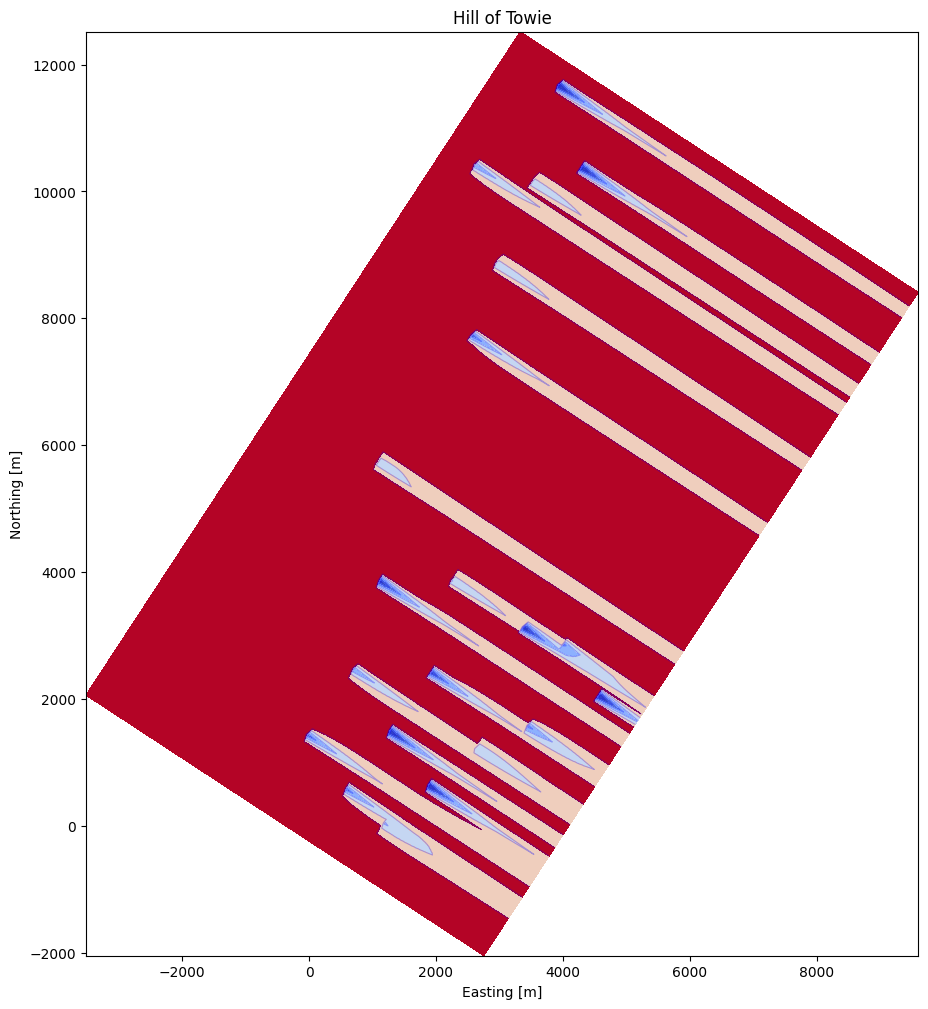

In [39]:
# Using the FlorisModel functions, get 2D slices.
x_bounds = [-500, 7000]
y_bounds = [-500, 12000]
z_bounds = [0.001, 500]
cross_plane_locations = [10, 1200, 2500]
horizontal_plane_location = 90.0
streamwise_plane_location = 0.0
# Contour plot colors
min_ws = 4
max_ws = 10

horizontal_plane = fmodel.calculate_horizontal_plane(
    x_resolution=200,
    y_resolution=100,
    height=horizontal_plane_location,
    x_bounds=x_bounds,
    y_bounds=y_bounds,
    findex_for_viz=1,
    # yaw_angles=yaw_angles,
)


fig, ax = plt.subplots(1, 1, figsize=(12, 12))
visualize_cut_plane(horizontal_plane, ax=ax, title="Hill of Towie", min_speed=min_ws, max_speed=max_ws)
ax.set_xlabel("Easting [m]")
ax.set_ylabel("Northing [m]")

In [42]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import PillowWriter


def create_wind_flow_gif(
    fmodel,
    horizontal_plane_location,
    x_bounds,
    y_bounds,
    min_ws,
    max_ws,
    num_frames=100,
    output_filename="wind_flow.gif",
):
    """
    Create a GIF animation of wind flow plots

    Parameters:
    -----------
    fmodel : your flow model object
    horizontal_plane_location : height for the horizontal plane
    x_bounds, y_bounds : spatial bounds for the plot
    min_ws, max_ws : wind speed bounds for visualization
    num_frames : number of frames (default 100)
    output_filename : name of output GIF file
    """

    # Set up the figure
    fig, ax = plt.subplots(1, 1, figsize=(12, 12))

    # Set up the writer for GIF creation
    writer = PillowWriter(fps=1)  # Adjust fps as needed

    with writer.saving(fig, output_filename, dpi=100):
        for findex in range(num_frames):
            # Clear the previous plot
            ax.clear()

            # Calculate horizontal plane for current findex
            horizontal_plane = fmodel.calculate_horizontal_plane(
                x_resolution=200,
                y_resolution=100,
                height=horizontal_plane_location,
                x_bounds=x_bounds,
                y_bounds=y_bounds,
                findex_for_viz=findex,
            )

            # Create the visualization
            visualize_cut_plane(
                horizontal_plane,
                ax=ax,
                title=f"Hill of Towie - Frame {findex + 1}/{num_frames}",
                min_speed=min_ws,
                max_speed=max_ws,
            )

            # Set labels
            ax.set_xlabel("Easting [m]")
            ax.set_ylabel("Northing [m]")

            # Add frame to GIF
            writer.grab_frame()

            # Optional: print progress
            if (findex + 1) % 10 == 0:
                print(f"Processed frame {findex + 1}/{num_frames}")

    plt.close(fig)
    print(f"GIF saved as {output_filename}")

In [43]:
create_wind_flow_gif(
    fmodel,
    horizontal_plane_location,
    x_bounds,
    y_bounds,
    min_ws,
    max_ws,
    num_frames=10,
    output_filename="wind_flow.gif",
)

Processed frame 10/10
GIF saved as wind_flow.gif


In [45]:
turbine_powers = fmodel.get_turbine_powers() / 1e6

In [46]:
turbine_powers.shape

(100, 21)

In [ ]:
# Look at the powers of each turbine
turbine_powers = fmodel.get_turbine_powers().flatten() / 1e6

num_in_row = len(layout_x)

fig0, ax0 = plt.subplots(1, 1)
width = 0.1
nw = -2
x = np.array(range(num_in_row)) + width * nw
nw += 1

title = "Original"
ax0.bar(x, turbine_powers, width=width, label=title)
ax0.legend()

# Visualize wakes
if show_flow_cuts:
    generate_wake_visualization(fmodel, title)

# Increase the base recovery rate
fmodel_dict_mod = copy.deepcopy(fmodel_dict)
fmodel_dict_mod["wake"]["wake_velocity_parameters"]["empirical_gauss"]["wake_expansion_rates"] = [
    0.03,
    0.015,
]
fmodel = FlorisModel(fmodel_dict_mod)
fmodel.set(wind_speeds=[8.0], wind_directions=[270.0])

fmodel.run()
turbine_powers = fmodel.get_turbine_powers().flatten() / 1e6

x = np.array(range(num_in_row)) + width * nw
nw += 1

title = "Increase base recovery"
ax0.bar(x, turbine_powers, width=width, label=title)

if show_flow_cuts:
    generate_wake_visualization(fmodel, title)

# Add new expansion rate
fmodel_dict_mod = copy.deepcopy(fmodel_dict)
fmodel_dict_mod["wake"]["wake_velocity_parameters"]["empirical_gauss"]["wake_expansion_rates"] = fmodel_dict["wake"][
    "wake_velocity_parameters"
]["empirical_gauss"]["wake_expansion_rates"] + [0.0]
fmodel_dict_mod["wake"]["wake_velocity_parameters"]["empirical_gauss"]["breakpoints_D"] = [5, 10]

fmodel = FlorisModel(fmodel_dict_mod)
fmodel.set(wind_speeds=[8.0], wind_directions=[270.0])

fmodel.run()
turbine_powers = fmodel.get_turbine_powers().flatten() / 1e6

x = np.array(range(num_in_row)) + width * nw
nw += 1

title = "Add rate, change breakpoints"
ax0.bar(x, turbine_powers, width=width, label=title)

if show_flow_cuts:
    generate_wake_visualization(fmodel, title)

# Increase the wake-induced mixing gain
fmodel_dict_mod = copy.deepcopy(fmodel_dict)
fmodel_dict_mod["wake"]["wake_velocity_parameters"]["empirical_gauss"]["mixing_gain_velocity"] = 3.0
fmodel = FlorisModel(fmodel_dict_mod)
fmodel.set(wind_speeds=[8.0], wind_directions=[270.0])

fmodel.run()
turbine_powers = fmodel.get_turbine_powers().flatten() / 1e6

x = np.array(range(num_in_row)) + width * nw
nw += 1

title = "Increase mixing gain"
ax0.bar(x, turbine_powers, width=width, label=title)

if show_flow_cuts:
    generate_wake_visualization(fmodel, title)

# Power plot aesthetics
ax0.set_xticks(range(num_in_row))
ax0.set_xticklabels([f"T{t}" for t in range(num_in_row)])
ax0.legend()
ax0.set_xlabel("Turbine")
ax0.set_ylabel("Power [MW]")

plt.show()

In [ ]:
# Define function for visualizing wakes
def generate_wake_visualization(fmodel: FlorisModel, title=None):
    y_plane = fmodel.calculate_y_plane(
        x_resolution=200,
        z_resolution=100,
        crossstream_dist=streamwise_plane_location,
        x_bounds=x_bounds,
        z_bounds=z_bounds,
        # yaw_angles=yaw_angles,
    )

    # Create the plots
    # Cutplane settings
    cp_ls = "solid"  # line style
    cp_lw = 0.5  # line width
    cp_clr = "black"  # line color
    fig = plt.figure()
    fig.set_size_inches(12, 12)
    # Horizontal profile
    ax = fig.add_subplot(311)

    ax.plot(x_bounds, [streamwise_plane_location] * 2, color=cp_clr, linewidth=cp_lw, linestyle=cp_ls)
    for cpl in cross_plane_locations:
        ax.plot([cpl] * 2, y_bounds, color=cp_clr, linewidth=cp_lw, linestyle=cp_ls)

    ax = fig.add_subplot(312)
    visualize_cut_plane(y_plane, ax=ax, title="Streamwise profile", min_speed=min_ws, max_speed=max_ws)
    ax.plot(x_bounds, [horizontal_plane_location] * 2, color=cp_clr, linewidth=cp_lw, linestyle=cp_ls)
    for cpl in cross_plane_locations:
        ax.plot([cpl, cpl], z_bounds, color=cp_clr, linewidth=cp_lw, linestyle=cp_ls)

    # Spanwise profiles
    for i, (cp, cpl) in enumerate(zip(cross_planes, cross_plane_locations)):
        visualize_cut_plane(
            cp,
            ax=fig.add_subplot(3, len(cross_planes), i + 7),
            title=f"Loc: {cpl:.0f}m",
            min_speed=min_ws,
            max_speed=max_ws,
        )

    # Add overall figure title
    if title is not None:
        fig.suptitle(title, fontsize=16)